# 04-Bootloader启动流程与App跳转


## 1. 本篇内容与实验目标

上一篇已经把文件通过 Ymodem 接收并写入 Flash。本篇继续解决：**写进去的 App 固件，怎样由 Bootloader 启动起来？** 对应讲义 `OTA远程升级.pdf` 第 **40—47 页**（PDF 物理页码）和以下视频。

| 视频 | 播放器显示时长 | 本篇重点 |
|---|---|---|
| `12_Bootloader启动到App_固件文件准备.mp4` | 3:57 | Keil 编译后用 fromelf 生成 bin 固件 |
| `13_Bootloader启动到App_启动流程&跳转准备.mp4` | 11:03 | 向量表、MSP、Reset_Handler、启动链路 |
| `14_Bootloader启动到App_跳转注意事项.mp4` | 8:20 | 分区链接、向量表与内存地址核对 |
| `15_Bootloader启动到App_代码实现跳转.mp4` | 16:22 | BootToApp、App 配置、编译与运行验证 |
| `16_Bootloader启动到App_总结与提炼.mp4` | 3:51 | 启动两要素、跳转四步和参数区引入 |

资料来自[课程百度网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。已读取视频 12、13、16 的完整自动中文字幕；14、15 未取得现成字幕，按播放器关键画面、讲义原图和配套源码交叉整理。字幕中的技术名词以源码为准。

实验平台为 **GD32F407VET6，512 KB 片上 Flash**。代码主要对照 `Code.zip` 中 `03_GD32F407_IAP_Bootloader3` 与 `04_GD32F407_IAP_App`，并核对 Bootloader4 的同名跳转函数。代码包已包含下一阶段的升级标记，所以本篇会明确区分“本课演示地址”与“后续工程地址”。本文未在本机连接开发板编译、烧录或测试，实验操作与现象按课堂材料整理。


## 2. 先准备 App 的原始二进制固件

打开 App 工程 `04_GD32F407_IAP_App/Project/GD32F407.uvprojx`。课程先观察编译输出：有 `.axf`，开启 HEX 输出时还有 `.hex`，但不会自然得到供 Ymodem 发送的 `.bin`。

| 文件 | 含义 | 本课用途 |
|---|---|---|
| `.axf` | ARM ELF 格式的可执行映像，可带符号、调试和段信息 | Keil 调试，以及 fromelf 转换的输入 |
| `.hex` | Intel HEX 文本记录，包含地址和校验等信息 | 供支持该格式的烧录工具解析 |
| `.bin` | 原始二进制字节，不自带目标 Flash 基址 | 作为升级文件，经 Ymodem 接收后写入 App 分区 |

**不能只把 `.hex` 或 `.axf` 改后缀为 `.bin`。** 本课接收端按字节写 Flash，没有解析 HEX 记录或 ELF 段表；发送错误格式会把封装信息也写入 App 区，起始位置就不再是有效向量表。

生成 bin 也不会自动改变程序链接地址。应先配置正确的 App 分区，再编译和转换，避免“文件能传完，程序却不能启动”。


## 3. Keil 中配置 fromelf：编译完成后自动转换

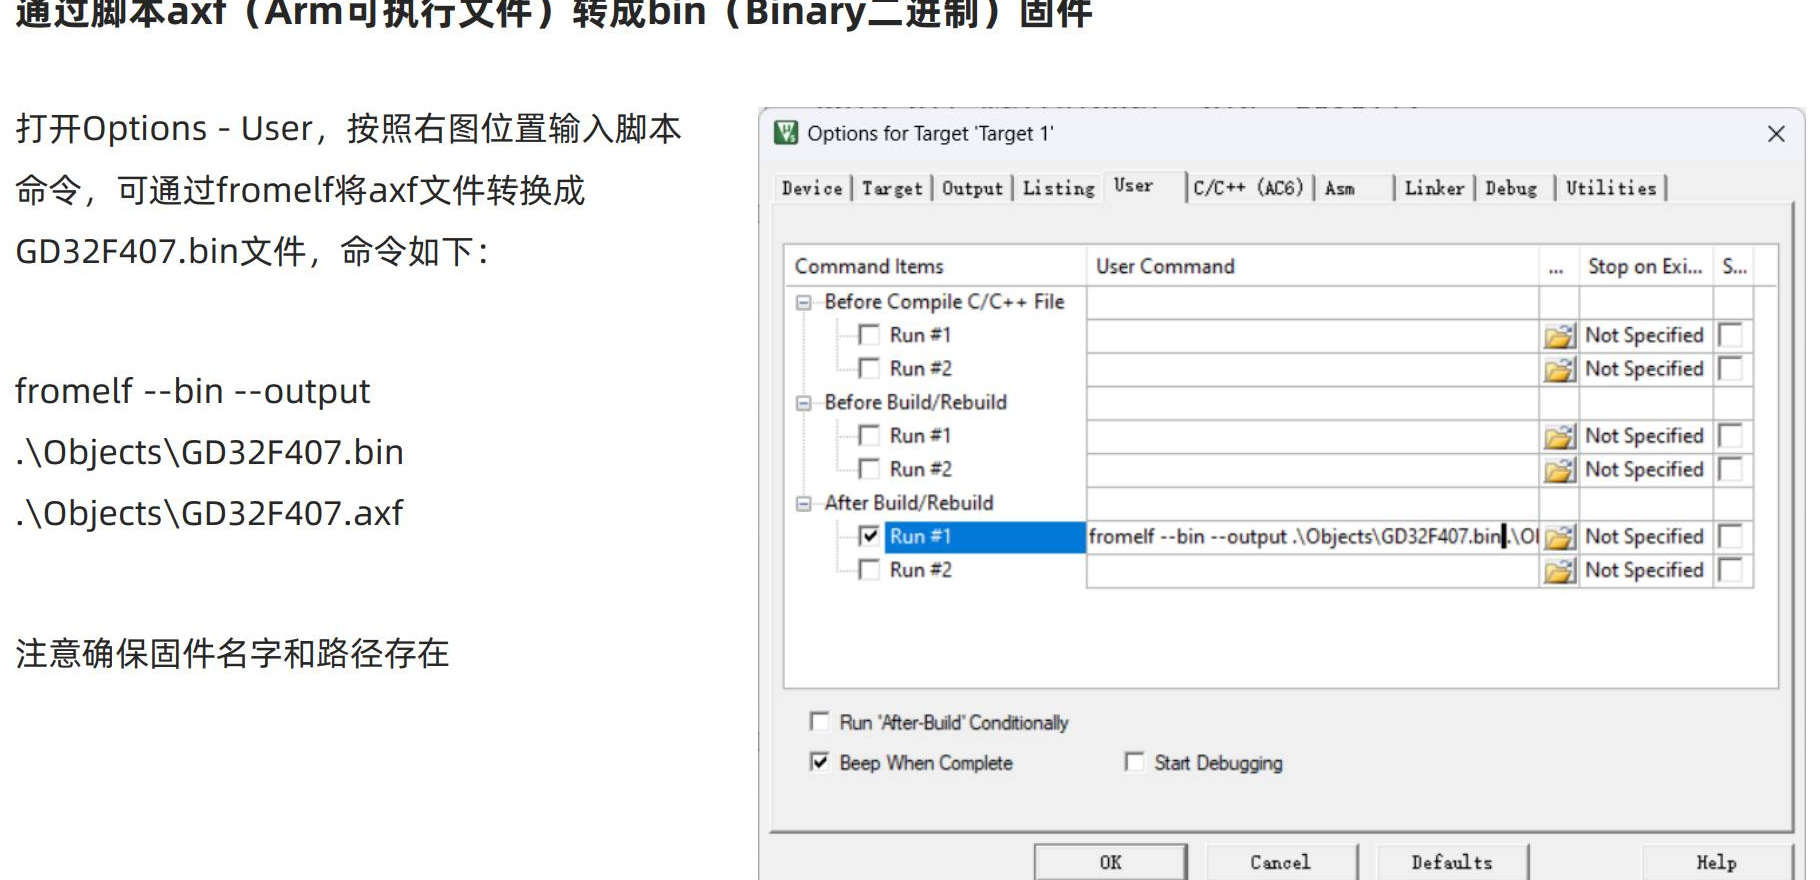

*讲义第 41 页，保留命令和 Keil User 设置窗口。图中脚本所在的 Run 槽位与代码包可以不同，作用一致。*

1. 打开 `Options for Target → Output`，确认输出目录是 `Objects`、输出名是 `GD32F407`。
2. 切到 `User`，在 **After Build/Rebuild** 中启用一个 `Run` 槽位。
3. 填入以下命令，点击 `OK` 后重新编译。

```text
fromelf --bin --output .\Objects\GD32F407.bin .\Objects\GD32F407.axf
```

`fromelf` 是 ARM 工具链提供的转换工具；`--bin` 指定输出原始二进制，`--output` 后面是输出文件，最后一项是输入的 axf 文件。相对路径按工程工作目录解释，文件名和目录必须与实际输出一致。

代码包 App 工程的 After Build 配置中，Run #1 是 `./keil5_disp_size_bar.exe`，用于显示占用信息；Run #2 才是上述 fromelf 命令。课程用启动计算器的例子说明“编译后运行命令”的含义，正式生成固件时保留转换命令即可，无需运行演示程序。

完成后检查 `Project/Objects/GD32F407.bin` 的修改时间和大小，避免误发旧文件。代码包附带的 App bin 为 **7272 字节**；这是资料中的构建产物，不是要求每次编译必须得到的固定大小。


## 4. 单片机启动时，main 之前还发生了什么

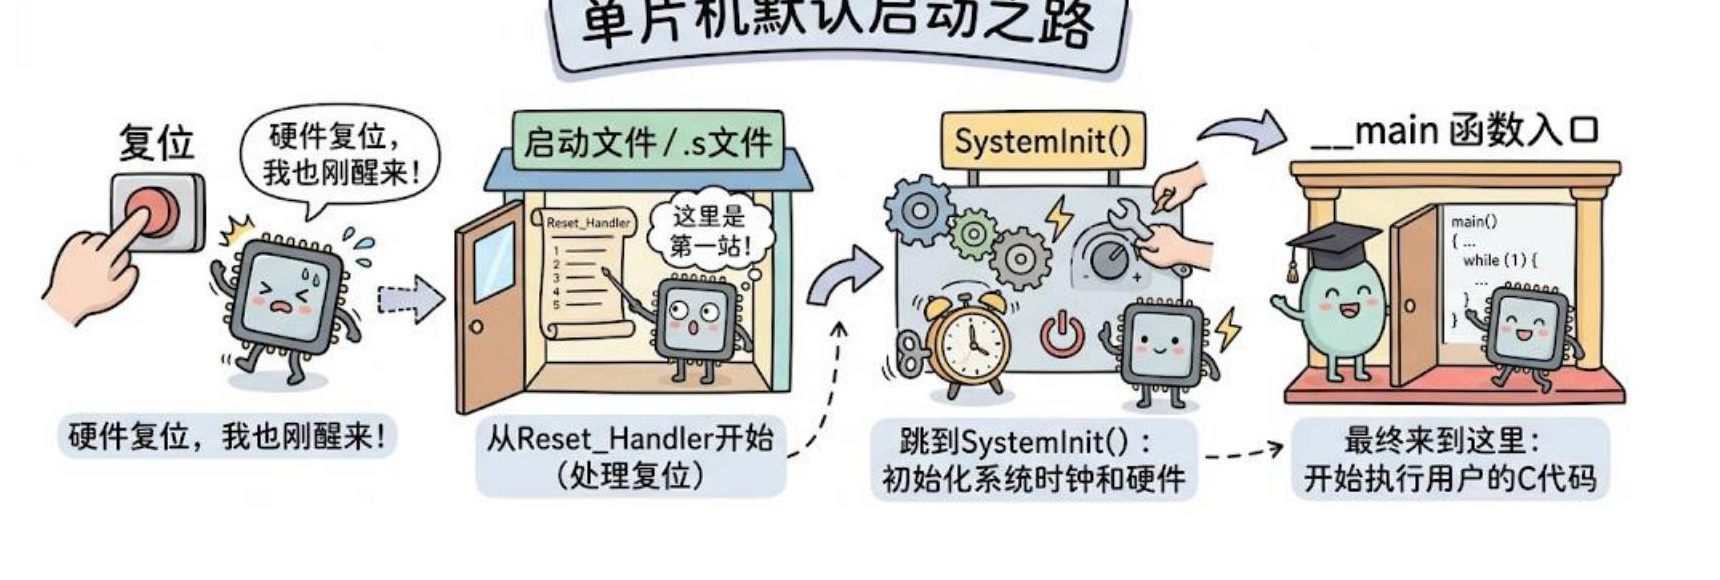

*讲义第 43 页：复位、启动文件、SystemInit 和用户 main 的先后关系。C 运行库入口可在实际启动文件中继续确认。*

正常从主 Flash 启动时，启动链路可写为：

```text
上电／复位，选择启动存储区
→ 硬件从向量表取得初始 MSP 和 Reset_Handler
→ 执行启动文件里的 Reset_Handler
→ SystemInit()：初始化系统时钟等底层设置
→ C 运行库入口 __main：准备程序运行环境
→ 用户 main()
```

这里的 `__main` 与用户编写的 `main` 是两个入口。运行库负责数据段、零初始化段等 C 运行环境的准备，之后才调用用户函数。

课程说“软件模拟上电启动”，核心是让 App 重新走它自己的启动链路。**跳转不会自动把所有外设和内核状态恢复成硬件复位值**，因此还需要处理 Bootloader 留下的中断和外设状态。


## 5. 从启动文件找到向量表的前两个字

App 的启动文件为 `Firmware/CMSIS/GD/GD32F4xx/Source/ARM/startup_gd32f407_427.s`，关键部分如下：

```asm
__Vectors       DCD     __initial_sp
                DCD     Reset_Handler
                DCD     NMI_Handler
                DCD     HardFault_Handler
                ; 后续异常和外设中断入口……
```

`DCD` 定义一个 32 位字。本课最先关注前两个字，也就是固件最前面的 8 个字节：

| App 区内偏移 | 保存的数据 | 使用方式 |
|---|---|---|
| `+0`，第 1 个 32 位字 | `__initial_sp`，初始栈顶地址 | 读出后写入 MSP |
| `+4`，第 2 个 32 位字 | `Reset_Handler` 的入口地址 | 读出后转成函数指针，启动 App |
| `+8` 及之后 | NMI、HardFault、其他异常和中断入口 | 异常发生时通过向量表定位处理函数 |

向量表首项是 **RAM 中的栈顶地址**，不是代码指令；第二项是 **入口地址的数值**，也不是 Reset_Handler 函数体本身。因此不能直接把 `APP_ADDR_IN_FLASH` 当作普通函数地址调用。

**MSP（Main Stack Pointer）**决定主栈的位置；**PC（Program Counter）**决定执行哪条指令。课程所谓“设置 PC”，在 C 代码中由函数指针调用产生的跳转实现。


## 6. Reset_Handler 怎样把程序带到用户 main

配套 App 的启动文件保留了下面这段流程：

```asm
Reset_Handler   PROC
                EXPORT  Reset_Handler [WEAK]
                IMPORT  SystemInit
                IMPORT  __main
                LDR     R0, =SystemInit
                BLX     R0
                LDR     R0, =__main
                BX      R0
                ENDP
```

先调用 `SystemInit`，返回后再进入 `__main`。这说明 Bootloader 的目标应该是 **App 向量表中保存的 Reset_Handler**，然后让 App 自己完成后续初始化。

若直接跳到用户 `main()`，就绕过了这条启动路径。全局变量初始化、运行库和系统设置都可能不符合 App 的预期，程序即使短暂运行，也不能据此认为启动过程正确。

本课按“从主 Flash 启动”的常规配置讲解。`0x08000000` 是主 Flash 的物理基址；复位取向量还涉及启动映射和启动模式。不要把“从 Flash 启动”推广为任何 BOOT 配置下都固定从这个物理地址启动。


## 7. Bootloader 与 App 为什么能共存在同一块 Flash

Bootloader 和 App 是两个独立编译的固件。Bootloader 固定放在主 Flash 前部，负责接收、写入和启动 App；App 放在后面的分区，负责具体业务。

本课先用 **16 KB Bootloader + App** 演示跳转；视频 16 再引出参数区，后续代码包已采用第二种布局：

| 阶段 | Bootloader | 参数区 | App 起点 | App 向量表偏移 |
|---|---|---|---|---|
| 视频 13—15、讲义演示 | `0x08000000—0x08003FFF` | 未单列 | `0x08004000` | `0x4000` |
| Bootloader3/4 与配套 App 工程 | `0x08000000—0x08003FFF` | `0x08004000—0x08007FFF` | `0x08008000` | `0x8000` |

以代码包布局为例：

```text
0x08000000        0x08004000        0x08008000                       0x08080000
     | Bootloader 16KB | 参数区 16KB |          App 480KB                 |
                                                                      ↑
                                                            Flash 结束边界，不包含
```

512 KB Flash 的有效末地址是 `0x0807FFFF`。加入参数区后，App 可用大小为 `0x80000 - 0x4000 - 0x4000 = 0x78000`，即 **480 KB**；仅保留 Bootloader 时则为 `0x7C000`，即 **496 KB**。

后续源码仍有注释写着“取出 0x08004000／0x08004004”。实际执行的是宏 `APP_ADDR_IN_FLASH` 和 `APP_ADDR_IN_FLASH + 4`，应以宏的求值结果为准，不能照抄旧注释。


## 8. App 配置之一：修改工程的 Flash 链接起点

在 App 工程中打开 `Options for Target → Target → Read/Only Memory Areas → IROM1`，修改 `Start`，让链接器按 App 实际分区生成地址。

| 配置项 | 本课演示布局 | 含参数区的后续布局 |
|---|---|---|
| Bootloader 的 IROM1 Start | `0x08000000` | `0x08000000` |
| Bootloader 的 IROM1 Size | `0x4000` | `0x4000` |
| App 的 IROM1 Start | `0x08004000` | `0x08008000` |
| App 的 IROM1 Size 上限 | `0x7C000` | `0x78000` |

修改后必须 **重新编译并重新生成 bin**。程序中的入口、函数和向量地址由链接结果决定；不能把原来为 `0x08000000` 编译的 bin 随便搬到后面的地址，再期待它自动适应。

**代码包核对：**App 的 `.uvprojx` 中，IROM1 对应区域的 Start 已是 `0x08008000`，但 Size 仍保留 `0x80000`。对这块 512 KB 芯片，迁移起点后应把可用 Size 限制为 `0x78000`，防止链接器误允许超出 Flash 末端。附带 bin 很小，尚未触及这个边界。

这里的 IROM1 是链接配置，不要与下载算法窗口中表示整片物理 Flash 范围的起点、容量混为一谈。


## 9. App 配置之二：把中断向量表切换到 App

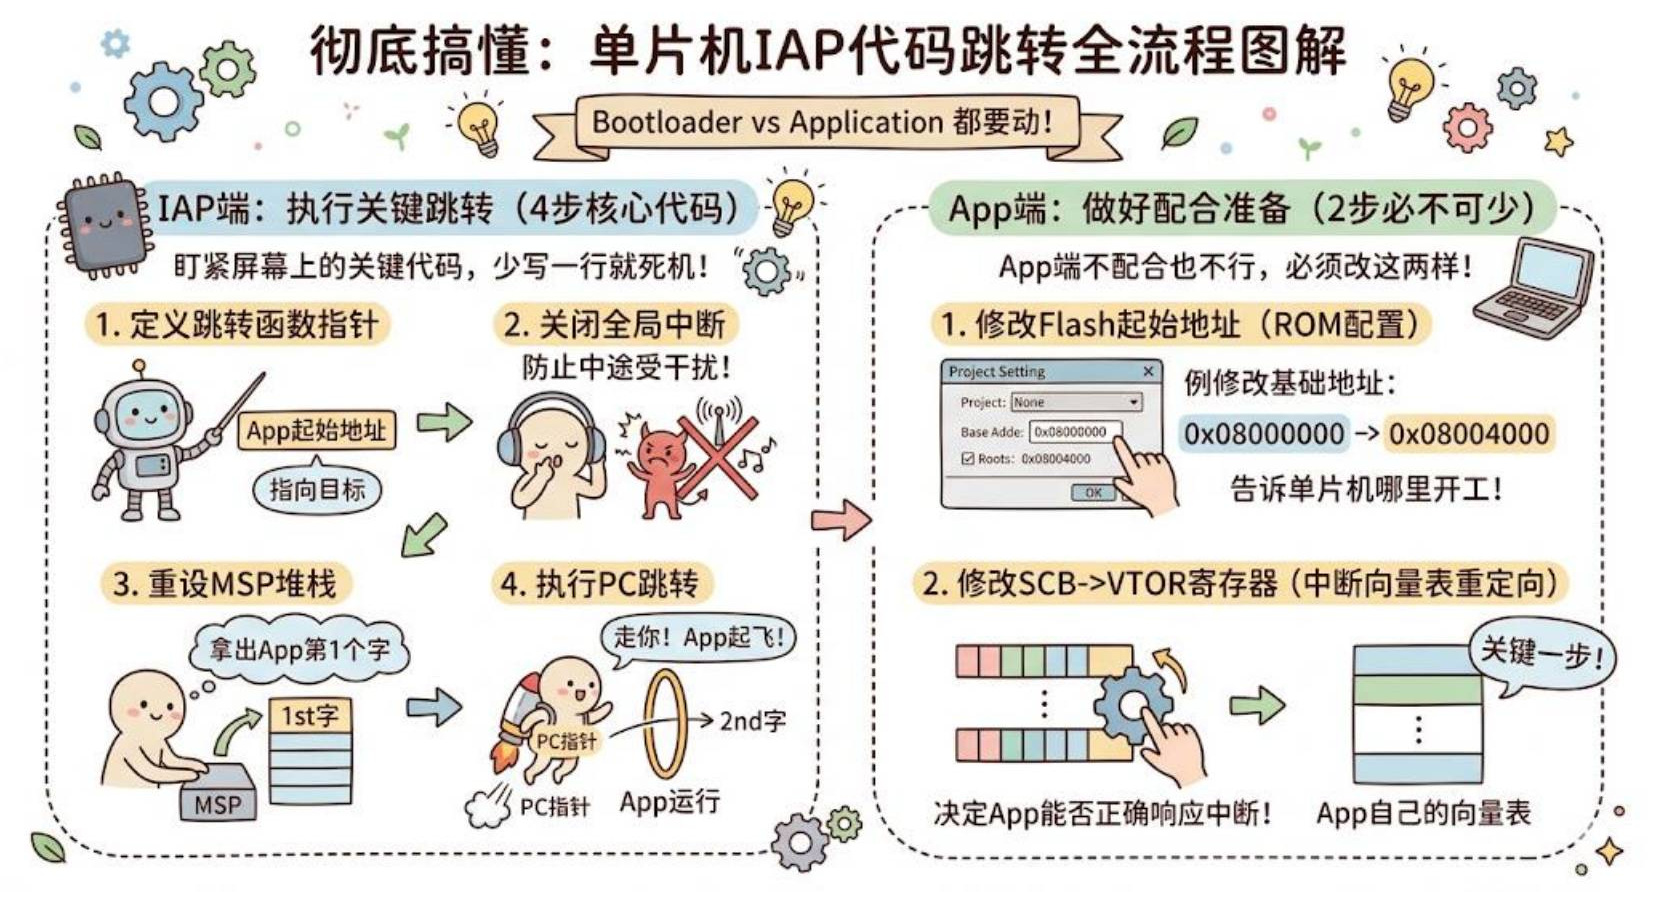

*讲义第 45 页：左侧为 Bootloader 跳转，右侧为 App 的链接地址与中断向量表配置。图中地址使用早期演示布局。*

链接到新地址后，还要让处理器在中断发生时使用 **App 自己的向量表**。配套 App 的 `Common/iap_driver.c`：

```c
void iap_init_irq(void) {
    nvic_vector_table_set(NVIC_VECTTAB_FLASH, VECTOR_OFFSET);
    __enable_irq();
}
```

本课演示把第二个参数直接写成 `0x4000`；后续工程通过 `VECTOR_OFFSET` 得到 `0x8000`。第一个参数为 Flash 基址，第二个参数是相对于它的偏移，最终使 `SCB->VTOR` 指向 App 向量表：

```text
演示：0x08000000 + 0x4000 = 0x08004000
后续：0x08000000 + 0x8000 = 0x08008000
```

`User/main.c` 在进入 App 的 `main()` 后首先调用 `iap_init_irq()`，然后才配置中断分组、SysTick、延时、串口和 GPIO。

“程序已进入 App 的 main”只能说明普通指令流跳过去了。若 VTOR 仍指向 Bootloader，定时器、串口等中断仍会按旧表取入口，可能跑入 Bootloader 的处理函数或故障处理函数。


## 10. 四处配置必须采用同一个 App 起点

复现跳转时，先按下面这张表核对，不能把两套布局混在一起：

| 位置 | 演示布局 | 后续工程布局 |
|---|---|---|
| App 工程的 IROM1 Start | `0x08004000` | `0x08008000` |
| Ymodem 接收后的 Flash 写入起点 | `0x08004000` | `0x08008000` |
| Bootloader 读取向量的 `APP_ADDR_IN_FLASH` | `0x08004000` | `0x08008000` |
| App `VECTOR_OFFSET` | `0x4000` | `0x8000` |

最后一行填的是 **偏移量**，其余三行填的是 **完整地址**。关系始终为：

```text
Flash 基址 + VECTOR_OFFSET
    = App 链接起点
    = App 实际写入起点
    = Bootloader 读取向量表的位置
```

改分区后只改一个宏还不够。需要同时确认 Bootloader 与 App 的配置、工程链接参数，并发送重新生成的固件；分区定义最好由双方共享，减少不同步的机会。


## 11. 跳转之前：先处理 Bootloader 遗留的中断状态

课程强调先执行 `__disable_irq()`，防止正在切换栈和入口时被普通中断打断。例如 Bootloader 启动了定时器，跳到 App 之后它仍可能继续计数；如果中断入口、全局变量或驱动状态已经变化，后续中断就可能破坏运行。

需要分清这些动作的含义：

| 动作 | 解决的问题 | 不能替代的操作 |
|---|---|---|
| `__disable_irq()` | 通过 PRIMASK 屏蔽普通可屏蔽中断 | 不会停掉定时器、DMA，也不会自动清除挂起状态；不屏蔽 NMI、HardFault |
| 停止已启用的中断源／外设 | 防止切换后仍产生旧事件 | 不会自动切换 VTOR |
| 处理 NVIC 使能、挂起状态及 SysTick | 减少旧异常状态被带入 App | 不会自动建立 App 的栈和 C 运行环境 |
| 配置 App 的 VTOR，按顺序恢复中断 | 让后续异常使用正确向量表 | 不能修复错误链接或损坏的固件 |

**工程补充：**配套 `BootToApp()` 仅调用 `__disable_irq()`，没有完整展示停止 SysTick、DMA、定时器及清理 NVIC 的过程。移植时应按 Bootloader 实际使用的硬件补齐。App 应在向量表和必要状态准备好后恢复中断，避免把课堂的简化示例当成通用交接模板。


## 12. BootToApp 的课堂核心代码

以下按 `Bootloader3/User/main.c` 整理，保留执行顺序、函数名和判断条件，删去重复注释。Bootloader4 的同名函数采用相同流程。

```c
typedef void (*FuncPtr)(void);

#define RAM_START_ADDR  0x20000000
#define RAM_SIZE        0x20000

void BootToApp(void) {
    uint32_t stackTopAddr =
        *((__IO uint32_t *)APP_ADDR_IN_FLASH);

    printf("stackTopAddr: 0x%08X\n", stackTopAddr);

    if (stackTopAddr >= RAM_START_ADDR &&
        stackTopAddr < (RAM_START_ADDR + RAM_SIZE)) {

        __disable_irq();
        __set_MSP(stackTopAddr);

        uint32_t resetHandlerAddr =
            *((__IO uint32_t *)(APP_ADDR_IN_FLASH + 4));

        printf("resetHandlerAddr: 0x%08X\n", resetHandlerAddr);

        FuncPtr jumpToApp = (FuncPtr)resetHandlerAddr;
        jumpToApp();

        printf("Boot End\r\n");
    } else {
        printf("栈顶地址不在合法范围, 无法启动\r\n");
    }
}
```

这段代码用来理解“取栈→设 MSP→取复位入口→函数指针跳转”。它依赖 `gd32f4xx.h`、分区宏和底层库，并不是能单独在电脑上运行的 C 程序；后文还会指出其交接与校验边界。


## 13. 解读指针：读地址中的值，再把值用作入口

先看读栈顶的表达式：

```c
uint32_t stackTopAddr = *((__IO uint32_t *)APP_ADDR_IN_FLASH);
```

`APP_ADDR_IN_FLASH` 是一个地址；强制转换把它看成指向 32 位数据的指针，最外层的 `*` 才读取这个地址里保存的值。`__IO` 在该库中表示 volatile 访问。

读复位入口时，宏是整数地址，所以 `APP_ADDR_IN_FLASH + 4` 前进 **4 字节**，正好指向第二个 32 位字。如果先定义 `uint32_t *vectors`，则应读取 `vectors[1]`，而不是误写成 `vectors[4]`。

```c
uint32_t resetHandlerAddr =
    *((__IO uint32_t *)(APP_ADDR_IN_FLASH + 4));

typedef void (*FuncPtr)(void);
FuncPtr jumpToApp = (FuncPtr)resetHandlerAddr;
jumpToApp();
```

`FuncPtr` 表示“无参数、无返回值的函数指针”。转换使用的是 **第二项中保存的值**，不是 `APP_ADDR_IN_FLASH + 4` 这个槽位的地址。启动 App 后，正常的 Reset_Handler／main 流程不应再返回 Bootloader；`Boot End` 只是原示例放在调用后的日志。


## 14. 用代码包中的 bin 核对前 8 字节

配套文件 `04_GD32F407_IAP_App/Project/Objects/GD32F407.bin` 长 7272 字节，按小端格式读出前两个 32 位字：

```text
文件偏移  原始字节           解释
0x0000    20 08 00 20       初始 MSP = 0x20000820
0x0004    9D 81 00 08       复位向量 = 0x0800819D
```

这是资料文件的静态检查结果，可与 Memory 窗口对照，不代表已经在开发板运行。

`0x20000820` 位于本示例使用的 SRAM 区内；`0x0800819D` 与后续 App 起点 `0x08008000` 对应。讲义早期演示使用的是 `0x0800419D`，与当时的 `0x08004000` 起点对应，两者不能互相替换。

**补充：**Cortex-M 使用 Thumb 指令集，函数入口指针的最低位通常为 1，用来表示 Thumb 状态。所以 `...19D` 是正常的向量表示，不能为了“地址对齐”随意把最低位清零再调用。做范围检查时可以用 `resetHandlerAddr & ~1u` 判断指令地址是否位于 App 的可执行区。


## 15. 栈顶合法性检查能发现什么，不能证明什么

课堂条件：

```c
stackTopAddr >= 0x20000000 && stackTopAddr < 0x20020000
```

`RAM_SIZE = 0x20000`，即 128 KB。这是本示例选择的 `0x20000000` SRAM 区间，不能当作所有 GD32 芯片的通用 RAM 范围，也没有覆盖该工程列出的其他 RAM 区域。

如果 App 区尚未写入、开头全为 `FF`，读到的栈顶会是 `0xFFFFFFFF`，这个条件能拦住它。若开头写入了文本或错误格式，通常也能发现明显异常。

但“首字落在 RAM 区间”只是一项粗检查，**不能证明固件完整或一定能执行**。更完整的检查还应结合实际链接布局确认栈对齐、栈空间，校验复位入口的 Thumb 位和范围，并验证固件长度与完整性。

**边界补充：**向下增长的栈允许初始空栈指针指向 RAM 尾端后一字节的边界，例如某些链接布局会使用 `0x20020000`。原代码用严格 `<` 会拒绝这种布局；是否允许等于上边界，应结合实际栈布局判断。本资料的 `0x20000820` 不受这个边界问题影响。


## 16. 教学跳转代码还需要哪些工程处理

保留课堂代码便于跟着理解，但实际移植时要注意以下限制：

| 源码中的做法 | 可能的问题 | 改进方向 |
|---|---|---|
| 只检查向量表第 1 项 | 入口可能是空值、错误地址或损坏内容 | 读取并检查两项向量，结合固件长度和完整性判断 |
| 只关全局中断 | 旧的中断源、挂起状态和外设仍存在 | 根据启动时启用的硬件执行交接清理 |
| 设置 MSP 后继续执行普通 C 代码、调用 printf | 编译器可能仍访问旧栈帧；改用 App 栈调用函数也可能破坏原状态 | 调试输出、校验和清理提前完成；最后用受控的底层交接切换栈并跳转，并检查生成指令 |
| App 在 main 开头直接恢复中断 | 中断恢复时某些驱动或共享状态可能尚未准备好 | 按 App 初始化依赖安排向量表、状态清理和中断恢复顺序 |

特别是 `__set_MSP()` 之后再 `printf()`，只适合观察本课演示思路，不应直接当作对编译优化、调用栈和任意运行环境都可靠的交接序列。

本课是在普通裸机主流程中启动 App。若 Bootloader 引入 RTOS、PSP、非特权模式或正在异常处理程序中，则还涉及额外的处理器状态，不能直接套用这个简化函数。


## 17. 按课堂思路完成“写入 App → 启动 App”实验

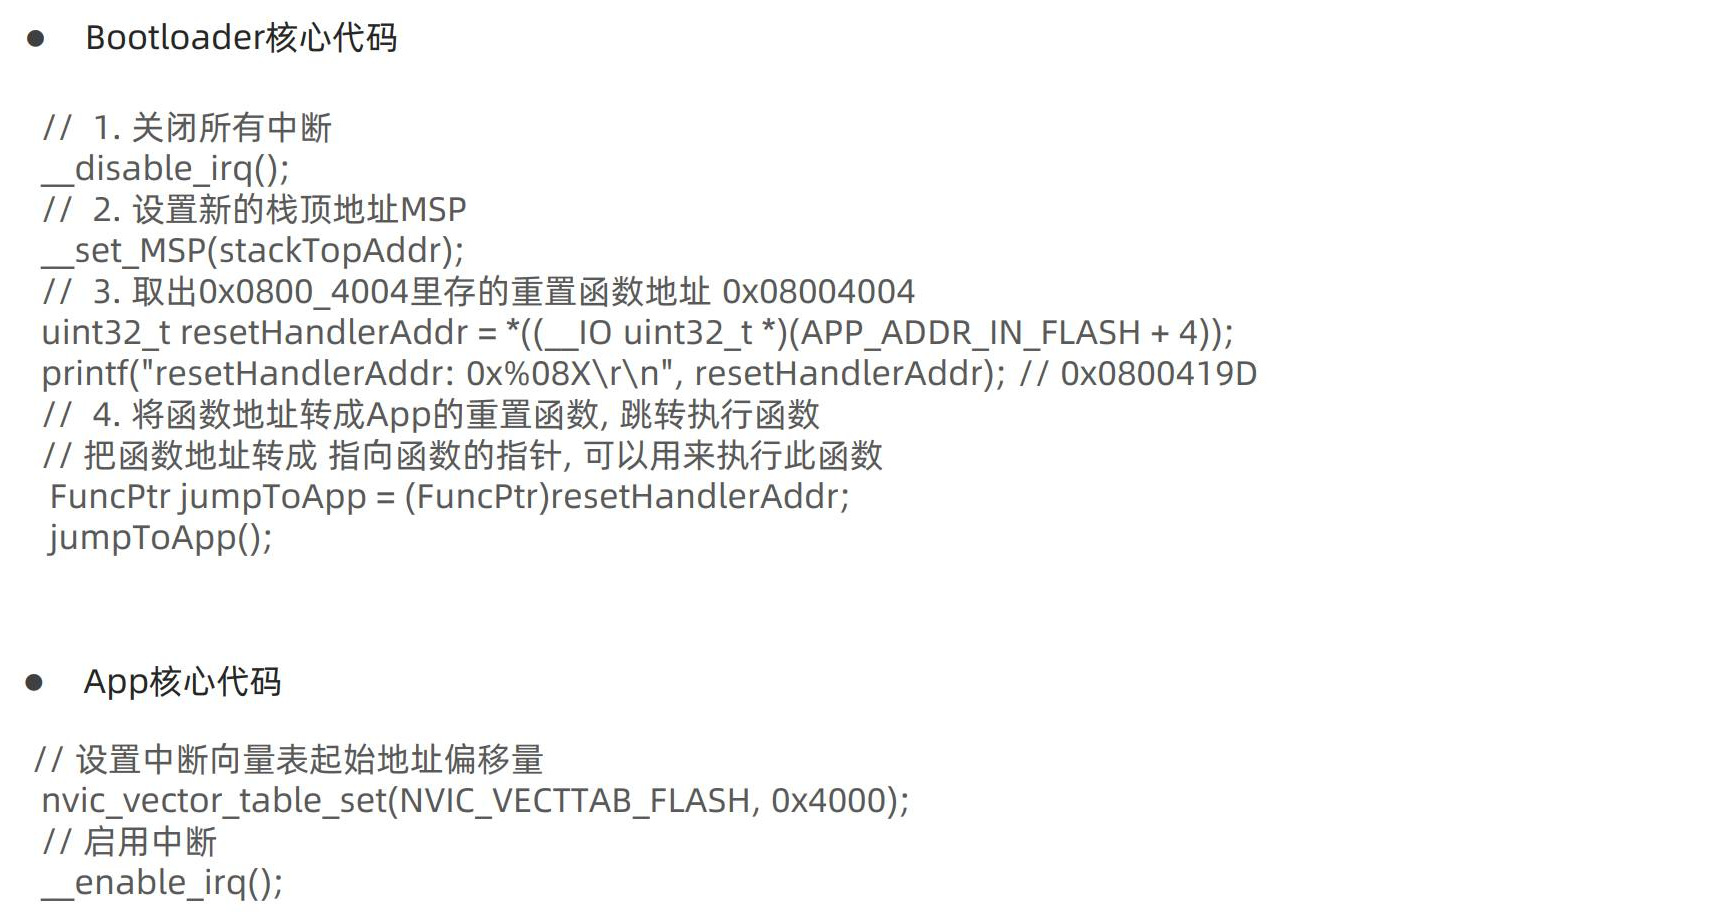

*讲义第 46 页，图中向量偏移仍为演示阶段的 `0x4000`。复现后续工程时使用 `VECTOR_OFFSET = 0x8000`。*

1. **选定一套分区。** 跟视频演示用 `0x08004000`；直接使用资料中的 Bootloader3 与 App 工程则按 `0x08008000` 核对。不要混搭。
2. **配置 App。** 修改 IROM1 起点与容量，配置 `iap_init_irq()`，在 App main 前部调用，加入清楚的版本／循环日志。
3. **编译 App。** 通过 After Build 生成新 bin，确认文件路径、时间和大小。
4. **配置 Bootloader。** 保留在 `0x08000000`，限制分区大小；核对 Ymodem 写入起点与 `BootToApp()` 读向量起点一致。
5. **先走接收分支。** 烧录 Bootloader，在 SecureCRT 使用上一课的 Ymodem 方式发送 App bin，等待接收与 Flash 写入完成。此时传的是可执行固件，不能再用文本文件代替。
6. **再走启动分支。** 视频 15 暂用条件分支选择 `UpdateApp()` 或 `BootToApp()`，先验证两个过程，再引出后续的升级标记控制。切换测试路径后重启，观察是否进入 App。
7. **验证中断和业务。** 除了 App 初始化日志，还要确认循环计数、延时、串口等继续正常，验证向量表切换后的运行。

**复现补充：**若为了切换临时分支而重新烧录 Bootloader，应检查下载器的擦除策略，避免整片擦除把已经接收的 App 一起清掉。调试器直接从 App 入口启动也不能替代“复位→Bootloader→App”这条完整路径的验证。


## 18. Memory、Map 和日志分别用来检查什么

| 检查手段 | 建议观察的位置／内容 | 能回答的问题 |
|---|---|---|
| Keil Memory | App 起点及 `+4` 的两个 32 位字 | 文件是否写到正确位置，MSP 和复位向量是否合理 |
| 向量表／启动文件 | `__Vectors`、`__initial_sp`、`Reset_Handler` | 固件起始数据和启动链路的来源 |
| 链接 Map 文件 | Reset_Handler 与各函数所属地址范围 | App 是否按选定分区链接，入口地址是否对应 |
| 调试寄存器 | MSP、PC、`SCB->VTOR` | 栈、执行流和中断向量基址是否切换正确 |
| 串口／LED | Bootloader 日志、App 版本、循环与外设行为 | 是否完成启动并持续正常运行 |

视频 14 展示了启动文件中的向量项，并查看链接结果中的函数地址；视频 15 编写 `BootToApp()` 和 App 的 `iap_init_irq()`，通过两边工程配合验证启动。

按配套源码，App 会打印 `App Init v1.0`，随后反复打印 `App run v1.0 -> ...`，并每 500 ms 翻转一次 PB2。复现时可将它们作为观察点；具体栈地址、Reset_Handler 数值、程序大小和计数会随构建改变。

不要把“串口传输成功”与“App 已启动”混为一件事。接收成功之后，还必须验证写入内容、启动地址和后续中断运行。


## 19. 为什么下一阶段要增加参数区

视频 16 提出：正常上电应该直接运行 App，需要更新时才进入接收流程；临时修改代码分支无法满足设备实际使用。因此要用 **可掉电保持的升级标记**，让 App 与 Bootloader 交换“下次启动需要升级”的意图。

代码包已把扇区 1 作为 16 KB 参数区，并将 App 后移到 `0x08008000`：

```c
#define FLASH_SIZE                0x80000
#define BOOTLOADER_SIZE           (16 * 1024)
#define PARAMETER_SIZE            (16 * 1024)
#define PARAM_ADDR_IN_FLASH       (0x08000000 + BOOTLOADER_SIZE)
#define APP_ADDR_IN_FLASH         (0x08000000 + BOOTLOADER_SIZE + PARAMETER_SIZE)
#define VECTOR_OFFSET             (BOOTLOADER_SIZE + PARAMETER_SIZE)
#define NEED_UPDATE_VERSION_FLAG  0xABCD
```

`SetUpdateVerFlag()` 写标记，`CheckNeedUpdate()` 检查标记，`ClearUpdateVerFlag()` 清理标记。Bootloader3 的 main 会检查标记，必要时调用 `UpdateApp()`，之后执行 `BootToApp()`。

这里仅解释代码包地址为何发生变化，**App 触发升级、复位回 Bootloader、倒计时与菜单两种模式放到第 05 篇**。源码目前在 `UpdateApp()` 返回后就清标记并尝试跳转，不能据此认为所有升级失败场景都有完整恢复处理。

参数区也可以设计在 Flash 末端，但本芯片大扇区的擦除代价和空间占用更高。课程选用前部 16 KB 扇区，因为即使只更新几个标志字节，也要以支持的擦除单位处理；不应让参数更新顺带擦掉 App 代码。


## 20. 常见问题与排查顺序

| 现象 | 优先检查 |
|---|---|
| 编译后没有 bin | After Build 的 Run 是否勾选、fromelf 命令是否执行、axf 路径和目标名是否正确 |
| bin 可以传完，但提示栈顶非法 | 是否发错文件格式、写入地址是否正确、App 区是否已擦空、首 4 字节是否真是 MSP |
| 读到的向量仍像文本或旧程序 | 是否选了旧文件，写入／擦除是否成功，检查 Memory 原始内容 |
| 跳转后马上 HardFault／卡死 | Reset_Handler 地址、Thumb 位、链接起点、实际写入地址和 MSP 是否一致且有效 |
| main 能进入，开中断就异常 | `VECTOR_OFFSET` 是否对应 App，VTOR 是否切换，Bootloader 是否遗留挂起中断或运行中的外设 |
| App 单独调试正常，经 Bootloader 启动不正常 | 检查中断、SysTick、时钟、外设和栈交接条件，确认不是调试器代替完成了启动准备 |
| 重新下载 Bootloader 后 App 不见了 | 下载时是否整片擦除，是否需要重新发送 App bin |
| 改了 App 分区起点仍运行旧地址 | 是否重新链接、重新生成 bin，以及双方是否混用了 `0x4000`／`0x8000` |

建议按 **文件格式 → 分区与实际内容 → 向量的两个字 → MSP／入口 → VTOR／中断 → 外设交接** 的顺序查，先确认静态地址，再排运行状态，避免只盯着最后一行函数指针调用。


## 21. 本篇总结与复习要点

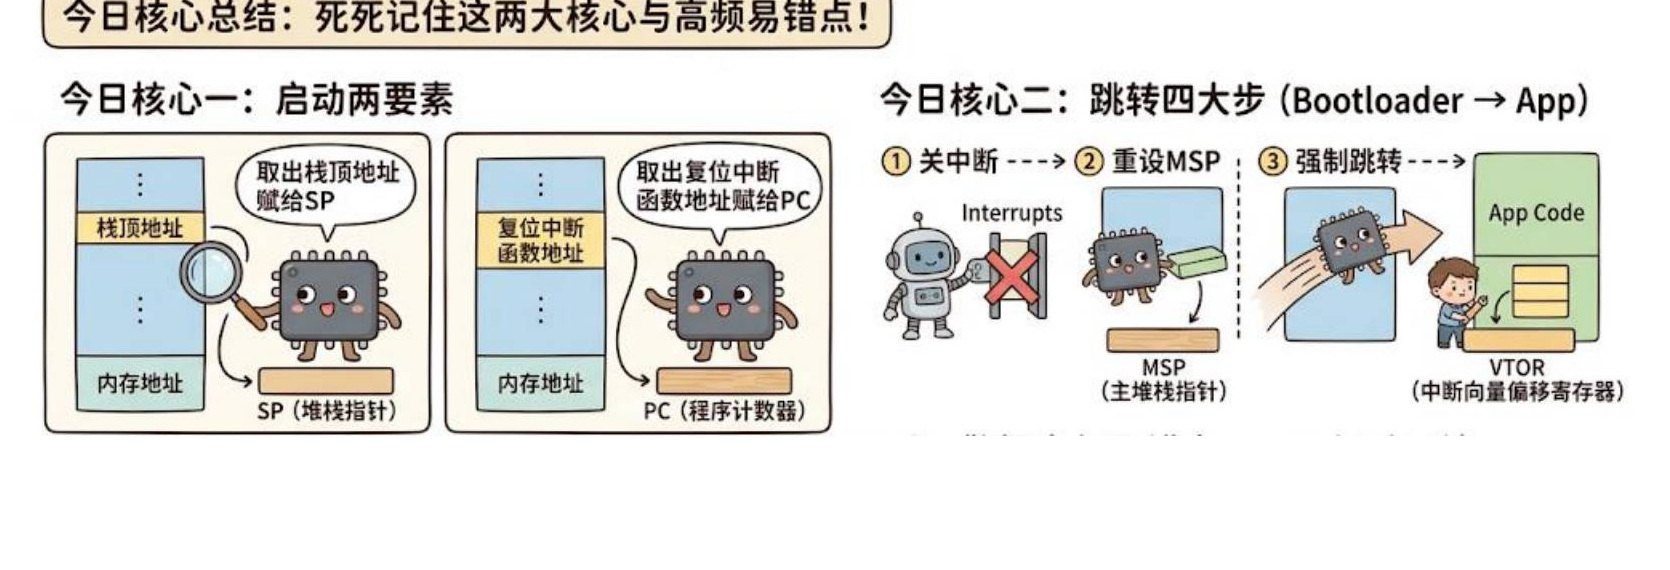

*讲义第 47 页：取栈顶、取复位入口，以及关闭中断、重设 MSP、跳转和向量表配置。*

**启动两个要素：**从 App 向量表第 1 个字读初始栈顶，交给 MSP；从第 2 个字读 Reset_Handler，通过函数指针启动 App 的完整初始化路径。

**串起四个步骤：**处理并关闭中断 → 重设 MSP → 跳入 App Reset_Handler → App 配置自己的向量表并按初始化顺序恢复中断。App 还必须提前按正确的 Flash 起点链接，接收端也必须把 bin 写到同一位置。

复习时应能回答：

1. 为什么不能把 App 起始地址直接当函数调用？——该地址首先保存的是栈顶数据，入口地址放在下一项。
2. 为什么跳 Reset_Handler，而不是直接跳 main？——让 App 执行 SystemInit 和 C 运行库初始化。
3. 为什么 main 已运行，中断仍可能出错？——普通执行流和异常向量入口由不同机制决定，还需要设置 VTOR 并处理旧中断状态。
4. 为什么讲义是 `0x08004000`，代码包却是 `0x08008000`？——后续增加了 16 KB 参数区，App 整体后移。
5. 为什么栈顶检查通过仍不能保证固件可用？——它只检查了向量表首项，尚未验证入口、完整性和交接状态。

把本篇与前两篇连起来，就是：**准备正确链接的 bin → Ymodem 接收 → Flash 擦写 → 检查向量 → 交接启动 → App 持续运行。** 下一篇再把“何时升级、何时启动”整理为完整串口升级流程。
